<a href="https://colab.research.google.com/github/devPartho3/Mern-Stack-Web-Dev-Marathon-/blob/main/X_ray_Image_Classification_with_PreTrained_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# X-ray Image Classification

In [ ]:
# importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

In [ ]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# setting the training data directory
DataDir = r''

In [ ]:
# intiallizing the category of classification
CATEGORIES = ["NORMAL", "PNEUMONIA"]

In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/chest_xray-20250726T110654Z-1-001.zip'


extract_path = '/content/chest_xray_data'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Unzip সফল হয়েছে!")
else:
    print("জিপ ফাইলটি এই পাথে পাওয়া যায়নি। দয়া করে ড্রাইভের সঠিক পাথটি চেক করুন।")


Unzip সফল হয়েছে!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


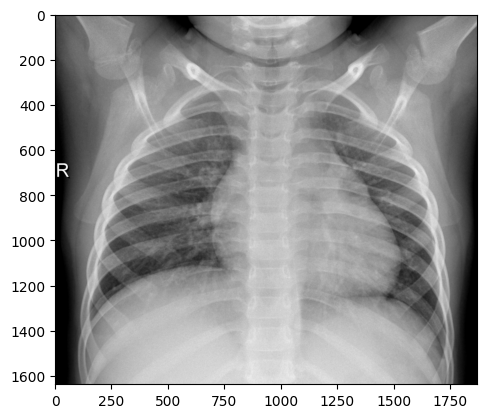

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

# এবার পাথ হবে আনজিপ করা ফোল্ডারটি
DataDir = "/content/chest_xray_data/chest_xray/train"
CATEGORIES = ['NORMAL', 'PNEUMONIA']

# আপনার মূল কোড
for i in CATEGORIES:
    path = os.path.join(DataDir, i)
    if not os.path.exists(path):
        print(f"Warning: Directory not found: {path}")
        continue
    try:
        for img in os.listdir(path):
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            if img_array is not None:
                plt.imshow(img_array, cmap='gray')
                plt.show()
                break
            else:
                print(f"Error reading image: {img}")
        break
    except Exception as e:
        print(f"Error: {e}")


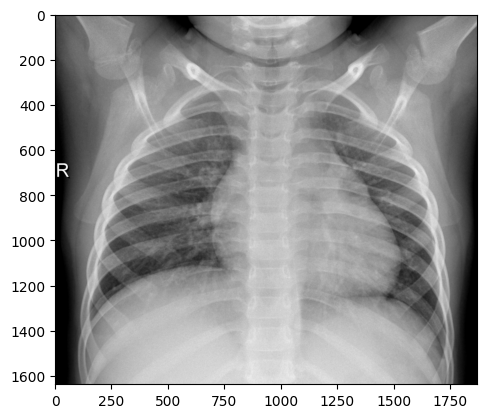

In [ ]:
# converting the images into grayscale
for i in CATEGORIES:
    path=os.path.join(DataDir,i)
    if not os.path.exists(path):
        print(f"Warning: Directory not found: {path}")
        print("Please verify your Google Drive path and folder names (case-sensitivity matters).")
        continue
    try:
        for img in os.listdir(path):
            img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
            plt.imshow(img_array,cmap='gray')
            plt.show()
            break
        break
    except FileNotFoundError as e:
        print(f"Error: {e}")
        print("Make sure your Google Drive sync has finished.")

In [ ]:
# Run this cell to list all files and folders in your Google Drive's root directory
# This helps verify the exact folder names and paths.
import os

my_drive_path = '/content/drive/MyDrive/'
if os.path.exists(my_drive_path):
    print("Items in your Google Drive root:")
    for item in os.listdir(my_drive_path):
        print(f"- {item}")
else:
    print("Google Drive is not mounted correctly. Please run the Mount cell (lHxQSqnvWGlr) first.")

Items in your Google Drive root:
- Colab Notebooks
- Untitled spreadsheet (1).gsheet
- img20220823_18525357.pdf
- img20220823_18543082.pdf
- dev.pdf
- Photo from dev481047
- bandicam 2024-04-25 20-29-55-553.mp4
- Classroom
- Lecture1_E.gdoc
- makeupLabfee.pdf
- Lecture7.gslides
- cs201-tree-graph.gslides
- D.S. Book-224-234 (1).gdoc
- D.S. Book-224-234.gdoc
- Untitled spreadsheet.gform
- Untitled spreadsheet.gsheet
- X_ray_Image_Classification - with PreTrained Models.ipynb
- chest_xray-20250726T110654Z-1-001.zip


In [ ]:
# intializing the size of the image so that every image should be in same dimension
img_size=100

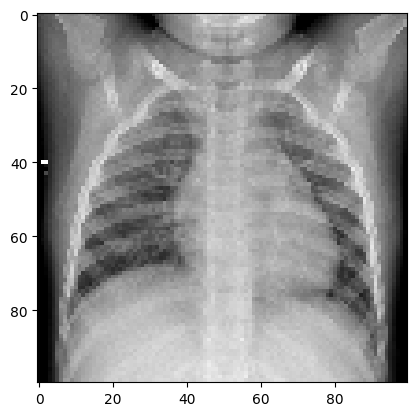

In [ ]:
# image after resize and gray scale
if 'img_array' in locals():
    new_array=cv2.resize(img_array,(img_size,img_size))
    plt.imshow(new_array,cmap='gray')
    plt.show()
else:
    print("Error: 'img_array' is not defined because the image folders in cell Syk5mJNh6Hrv could not be found or loaded.")
    print("Please verify your Google Drive directory structure before running this cell.")

In [ ]:
training_data=[]

In [ ]:
# defining the function for training data according to the categories converting the images into gray scale with resizing the image into 100 x 100
# converting it into numpy arrays
def create_training_data():
    for i in CATEGORIES:

        path=os.path.join(DataDir,i)
        class_num=CATEGORIES.index(i)

        for img in os.listdir(path):
            try:
                img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
                new_array=cv2.resize(img_array,(img_size,img_size))
                training_data.append([new_array,class_num])

            except Exception as e:
                pass

In [ ]:
# Check if the training directory exists before creating training data
import os
if os.path.exists(DataDir):
    create_training_data()
else:
    print(f"Error: The directory '{DataDir}' does not exist on your Google Drive.")
    print("Please upload the 'X-Ray Image Classification' folder to your Google Drive or update the path in cell 7-doGXdB6Hzz.")

In [ ]:
print(len(training_data))

5226


In [ ]:
import random
random.shuffle(training_data)
for sample in training_data[:10]:
    print(sample)

[array([[191, 180, 138, ..., 197, 190, 211],
       [180, 174, 164, ..., 192, 194, 208],
       [179, 180, 150, ..., 195, 195, 204],
       ...,
       [ 36,  35,  34, ...,  30,  29,  29],
       [ 36,  34,  34, ...,  30,  30,  30],
       [ 36,  35,  34, ...,  31,  31,  31]], dtype=uint8), 1]
[array([[ 0,  0, 12, ..., 12,  7,  0],
       [ 0,  0, 12, ...,  8,  3,  0],
       [ 0,  0,  9, ...,  6,  0,  0],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], dtype=uint8), 0]
[array([[ 43,  48,  50, ...,  76,  97, 167],
       [ 51,  53,  54, ...,  78, 104, 167],
       [ 51,  53,  54, ...,  74, 115, 166],
       ...,
       [ 24,  24,  24, ...,  99,  20,  14],
       [ 21,  24,  23, ..., 141,  20,   9],
       [ 24,  24,  23, ..., 136,  19,  13]], dtype=uint8), 1]
[array([[214, 227, 198, ...,   0,  72, 151],
       [213, 228, 218, ...,  17,  83, 147],
       [131, 220, 222, ...,   1,  71, 177],
       ...,
      

In [ ]:
X=[]
y=[]

In [ ]:
# spliting the features and labels
for features,label in training_data:
    X.append(features)
    y.append(label)

In [ ]:
# Reshape and print the first feature array if dataset exists
if len(X) > 0:
    print(X[0].reshape(-1, img_size, img_size, 1))
else:
    print("Error: The list 'X' is empty because no training images were loaded.")
    print("Please ensure your dataset is uploaded to Google Drive in the correct directory, then re-run the previous steps.")

[[[[191]
   [180]
   [138]
   ...
   [197]
   [190]
   [211]]

  [[180]
   [174]
   [164]
   ...
   [192]
   [194]
   [208]]

  [[179]
   [180]
   [150]
   ...
   [195]
   [195]
   [204]]

  ...

  [[ 36]
   [ 35]
   [ 34]
   ...
   [ 30]
   [ 29]
   [ 29]]

  [[ 36]
   [ 34]
   [ 34]
   ...
   [ 30]
   [ 30]
   [ 30]]

  [[ 36]
   [ 35]
   [ 34]
   ...
   [ 31]
   [ 31]
   [ 31]]]]


In [ ]:
y = np.array(y)

In [ ]:
# reshapping the features for making it compatible with tensorflow
X = np.array(X).reshape(-1,img_size,img_size,1)

In [ ]:
# as we do for training data similiarly doing with validation data
validation_data=[]
DataDir_val= r"/content/drive/MyDrive/X-Ray Image Classification/chest_xray/val"

In [ ]:
def create_validating_data():
    for i in CATEGORIES:

        path=os.path.join(DataDir_val,i)
        class_num=CATEGORIES.index(i)

        for img in os.listdir(path):
            try:
                img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
                new_array=cv2.resize(img_array,(img_size,img_size))
                validation_data.append([new_array,class_num])

            except Exception as e:
                pass

In [ ]:
# Check if the validation directory exists before running
import os
if os.path.exists(DataDir_val):
    create_validating_data()
    print(f"Loaded {len(validation_data)} validation samples.")
else:
    print(f"Error: The validation directory '{DataDir_val}' does not exist on your Google Drive.")
    print("Please upload the dataset or verify the path in cell 2AeBUCTC9HuW.")

Error: The validation directory '/content/drive/MyDrive/X-Ray Image Classification/chest_xray/val' does not exist on your Google Drive.
Please upload the dataset or verify the path in cell 2AeBUCTC9HuW.


In [ ]:
import random
random.shuffle(validation_data)
for sample in validation_data[:10]:
    print(sample)

In [ ]:
X_val=[]
y_val=[]

In [ ]:
for features,label in validation_data:
    X_val.append(features)
    y_val.append(label)

In [ ]:
y_val = np.array(y_val)
X_val=np.array(X_val).reshape(-1,img_size,img_size,1)

In [ ]:
# importing the library for training the model and adding the neural network layers
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense,Dropout,Activation,Flatten, Conv2D,MaxPooling2D
import pickle

In [ ]:
# Pixels value ranges from 0 to 255, 0 means black, 255 means white....
# In order to scale it down to a scale of 0 to 1, we are performing this step
X = X/255.0
x_val = X_val/255.0

In [ ]:
X.shape

(5226, 100, 100, 1)

In [ ]:
x_val.shape

(0, 100, 100, 1)

In [ ]:
# intializing the neural network layer for training the model
model= Sequential()

model.add(Conv2D(64,(3,3),input_shape=X.shape[1:]))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Conv2D(128,(3,3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Conv2D(256,(3,3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Flatten())
model.add(Dense(64))

model.add(Dropout(.5))
model.add(Dense(1))
model.add(Activation('sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# summary of the model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 98, 98, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 47, 47, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 21, 21, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,008,193 (7.66 MB)

 Trainable params: 2,008,193 (7.66 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [ ]:
# fitting the model with 10 epochs if data is available
if len(X) > 0:
    model.fit(X, y, batch_size=4, epochs=10, validation_data=(x_val, y_val))
else:
    print("Error: Cannot train the model because the training dataset 'X' is empty.")
    print("Please upload your dataset to Google Drive, verify your paths, and re-run the loading cells first.")

Epoch 1/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 26s 12ms/step - accuracy: 0.8905 - loss: 0.2820
Epoch 2/10
  13/1307 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.8488 - loss: 0.2581 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9445 - loss: 0.1474
Epoch 3/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9568 - loss: 0.1223
Epoch 4/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9592 - loss: 0.1140
Epoch 5/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9613 - loss: 0.0994
Epoch 6/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9686 - loss: 0.0860
Epoch 7/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9703 - loss: 0.0751
Epoch 8/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9740 - loss: 0.0714
Epoch 9/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9770 - loss: 0.0644
Epoch 10/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9747 - loss: 0.0719


In [ ]:
# saving the model
model.save(r"/content/drive/MyDrive/X-Ray Image Classification/chest_xray/model_10.h5")

In [ ]:
# importing the library for testing the model
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.models import load_model

In [ ]:
CATEGORIES = ["NORMAL", "PNEUMONIA"]

In [ ]:
# function for preparing the image for predicting the class
def prepare(image):
    img_size=100
    #img_array=cv2.imread(image,cv2.IMREAD_GRAYSCALE)
    img=tf.keras.preprocessing.image.load_img(image, color_mode='grayscale', target_size=(img_size,img_size))
    new_array=tf.keras.preprocessing.image.img_to_array(img)

    return new_array.reshape(-1,img_size,img_size,1)

In [ ]:
model = tf.keras.models.load_model("/content/drive/MyDrive/X-Ray Image Classification/chest_xray/model_10.h5")

In [ ]:
image = r'/content/drive/MyDrive/X-Ray Image Classification/chest_xray/test/NORMAL/IM-0059-0001.jpeg'

In [ ]:
# Use the correct unzipped local path instead of the Google Drive path
image = '/content/chest_xray_data/chest_xray/test/NORMAL/IM-0059-0001.jpeg'

prediction=model.predict([prepare(image)/255.0])
print(prediction)
print(round(prediction[0][0]))
print(CATEGORIES[int(round(prediction[0][0]))])

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=('Tensor(shape=(1, 100, 100, 1))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 878ms/step
[[0.01607691]]
0
NORMAL


In [ ]:
image2 = r'/content/drive/MyDrive/X-Ray Image Classification/chest_xray/test/PNEUMONIA/person1_virus_6.jpeg'


In [ ]:
# Use the correct unzipped local path for the pneumonia test image
image2 = '/content/chest_xray_data/chest_xray/test/PNEUMONIA/person1_virus_6.jpeg'

prediction=model.predict(prepare(image2)/255.0)
print(prediction)
print(round(prediction[0][0]))
print(CATEGORIES[int(round(prediction[0][0]))])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 505ms/step
[[0.9999751]]
1
PNEUMONIA


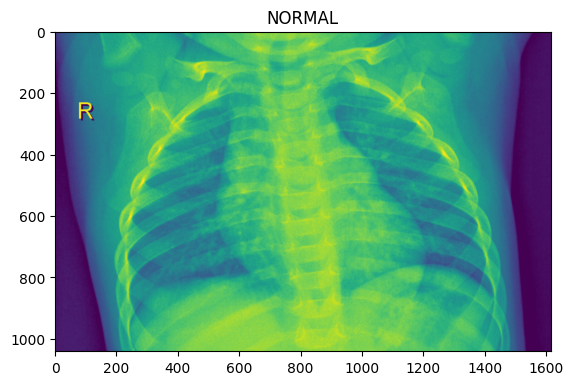

In [ ]:
img=mpimg.imread(image)
imgplot=plt.imshow(img)
plt.title(CATEGORIES[int(prediction[0][0])])
plt.show()

In [ ]:
# importing necessary libraries
import os
import cv2
import numpy as np
import tensorflow as tf
from keras.models import load_model

# Use the correct unzipped local path instead of the Google Drive path
test_dir = "/content/chest_xray_data/chest_xray/test"

# define categories
CATEGORIES = ["NORMAL", "PNEUMONIA"]

# set image size
img_size = 100

# load the saved model
model = load_model('/content/drive/MyDrive/X-Ray Image Classification/chest_xray/model_10.h5')

# initialize lists for storing test data
X_test = []
y_test = []

# loop through the test data directory and extract the images and their labels
for category in CATEGORIES:
    path = os.path.join(test_dir, category)
    class_num = CATEGORIES.index(category)
    for img in os.listdir(path):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (img_size, img_size))
            X_test.append(new_array)
            y_test.append(class_num)
        except Exception as e:
            pass

# convert test data to numpy arrays
X_test = np.array(X_test).reshape(-1, img_size, img_size, 1)
y_test = np.array(y_test)

# normalize test data
X_test = X_test / 255.0

# calculate test accuracy
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)

# print test accuracy
print('Test accuracy:', test_acc)

20/20 - 2s - 123ms/step - accuracy: 0.7484 - loss: 1.1247
Test accuracy: 0.7483974099159241


## Pre-Trained Models

In [ ]:
# import necessary libraries
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# define image size
img_size = 100

# load the pre-trained model (VGG16)
base_model = VGG16(input_shape=(img_size,img_size,3), include_top=False, weights='imagenet')

# freeze the layers of the pre-trained model
for layer in base_model.layers:
    layer.trainable = False

# add custom layers for classification
x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
x = Dense(64, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)

# create a new model
model = Model(inputs=base_model.input, outputs=predictions)

# compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# define the image generators for training and validation data
train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1./255)

# specify the correct unzipped local directories
train_dir = '/content/chest_xray_data/chest_xray/train'
val_dir = '/content/chest_xray_data/chest_xray/val'

# create the image generators for training and validation data
train_generator = train_datagen.flow_from_directory(train_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary')
val_generator = val_datagen.flow_from_directory(val_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary')

# train the model
model.fit(train_generator, epochs=10, validation_data=val_generator)

# evaluate the model on test data
test_dir = '/content/chest_xray_data/chest_xray/test'
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(test_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary', shuffle=False)
test_loss, test_acc = model.evaluate(test_generator)
print('Test accuracy:', test_acc)

Found 5226 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 95s 523ms/step - accuracy: 0.8965 - loss: 0.2472 - val_accuracy: 0.8750 - val_loss: 0.2329
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 77s 470ms/step - accuracy: 0.9370 - loss: 0.1611 - val_accuracy: 0.8125 - val_loss: 0.2721
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 81s 492ms/step - accuracy: 0.9514 - loss: 0.1409 - val_accuracy: 0.7500 - val_loss: 0.2978
Epoch 4/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 80s 488ms/step - accuracy: 0.9481 - loss: 0.1357 - val_accuracy: 0.6875 - val_loss: 0.3315
Epoch 5/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 79s 480ms/step - accuracy: 0.9529 - loss: 0.1315 - val_accuracy: 0.8750 - val_loss: 0.2841
Epoch 6/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 77s 472ms/step - accuracy: 0.9487 - loss: 0.1316 - val_accuracy: 0.7500 - val_loss: 0.3519
Epoch 7/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 79s 480ms/step - accuracy: 0.9543 - loss: 0.1250 - val_accuracy: 0.8750 - val_loss: 0.2884
E

In [ ]:
# saving the pre-trained model
model.save(r"/content/drive/MyDrive/X-Ray Image Classification/chest_xray/custom_pre_trained_model_10.h5")

In [ ]:
model = tf.keras.models.load_model("/content/drive/MyDrive/X-Ray Image Classification/chest_xray/custom_pre_trained_model_10.h5")

In [ ]:
model.summary()

In [ ]:
# evaluate the model on test data
test_dir = '/content/drive/MyDrive/X-Ray Image Classification/chest_xray/test'
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(test_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary', shuffle=False)
test_loss, test_acc = model.evaluate(test_generator)
print('Test accuracy:', test_acc)